# Feature Engineering

## Objective

The objective of this step is to transform validated Competence variables into meaningful features for machine learning model development.

Feature engineering includes construct-level feature creation, feature selection, and preparation of the final modelling dataset.

In [30]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Load Phase 02 Prepared Dataset

The prepared dataset containing validated Competence and Employability variables is used for feature engineering.

In [31]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase2_competence":
    PROJECT_DIR = PROJECT_DIR.parent.parent


DATA_FILE = (
    PROJECT_DIR
    /
    "data"
    /
    "processed"
    /
    "phase2_competence_prepared.csv"
)


df = pd.read_csv(DATA_FILE)


print(df.shape)

df.head()

(1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


## Define Target Variable

Employability average score (EVS_avg) is used as the dependent variable for prediction.

The model objective is to predict employability using competence features.

In [32]:
TARGET = "EVS_avg"

y = df[TARGET]


y.head()

0    4.750000
1    3.500000
2    3.750000
3    4.000000
4    4.333333
Name: EVS_avg, dtype: float64

## Create Competence Feature Sets

Two feature representations are prepared:

1. Item-level competence features
2. Construct-level competence features

Feature Set 1

In [33]:
competence_items = [
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "C6",
    "C7",
    "C8",
    "C9",
    "C10"
]


X_item = df[
    competence_items
]


X_item.head()

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10
0,3,3,4,4,3,3,3,3,4,3
1,3,4,4,3,4,4,4,4,4,3
2,3,4,3,3,3,4,3,4,4,3
3,4,4,4,4,4,4,4,4,4,3
4,4,4,4,4,4,5,5,4,4,5


Feature Set 2

In [34]:
competence_constructs = [
    "LifeCareer_avg",
    "LearningInnovation_avg",
    "ITMedia_avg"
]


X_construct = df[
    competence_constructs
]


X_construct.head()

,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg
0,3.50,3.000000,3.333333
1,3.50,4.000000,3.666667
2,3.25,3.333333,3.666667
3,4.00,4.000000,3.666667
4,4.00,4.666667,4.333333


## Feature Representation Comparison

Two feature representations were considered during feature engineering:

1. Item-level Competence features:
   - C1 to C10

2. Construct-level Competence features:
   - LifeCareer_avg
   - LearningInnovation_avg
   - ITMedia_avg

Item-level features were selected as the final machine learning input because they preserve detailed information from individual questionnaire items and allow machine learning algorithms to identify complex patterns.

In [35]:
feature_comparison = pd.DataFrame({

    "Feature_Set": [
        "Item_Level",
        "Construct_Level"
    ],

    "Number_of_Features":[
        len(competence_items),
        len(competence_constructs)
    ]
})


feature_comparison

,Feature_Set,Number_of_Features
0,Item_Level,10
1,Construct_Level,3


Feature Correlation Analysis

In [36]:
feature_target_corr = (
    df[
        competence_items + [TARGET]
    ]
    .corr()[TARGET]
    .sort_values(
        ascending=False
    )
)


feature_target_corr

EVS_avg    1.000000
C7         0.578631
C8         0.565592
C9         0.560505
C6         0.559574
C10        0.557692
C1         0.551998
C5         0.526432
C2         0.508955
C4         0.494869
C3         0.480282
Name: EVS_avg, dtype: float64

Visualize Feature Importance by Correlation

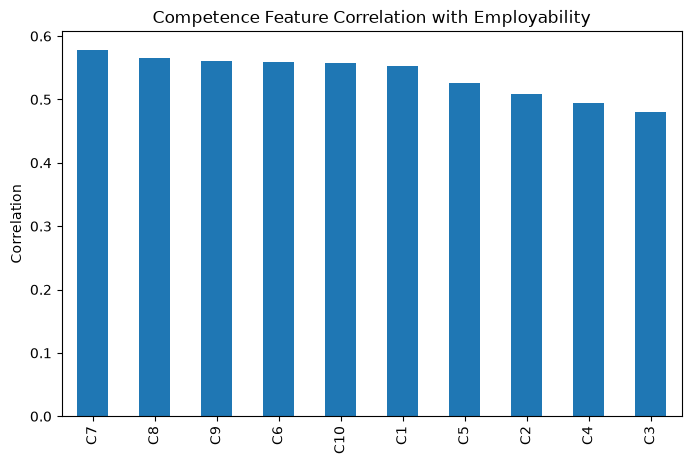

In [37]:
plt.figure(figsize=(8,5))


feature_target_corr.drop(
    TARGET
).plot(
    kind="bar"
)


plt.title(
    "Competence Feature Correlation with Employability"
)


plt.ylabel(
    "Correlation"
)


plt.show()

## Feature Correlation Check

Feature correlation is analyzed to identify highly related predictors before machine learning model development.

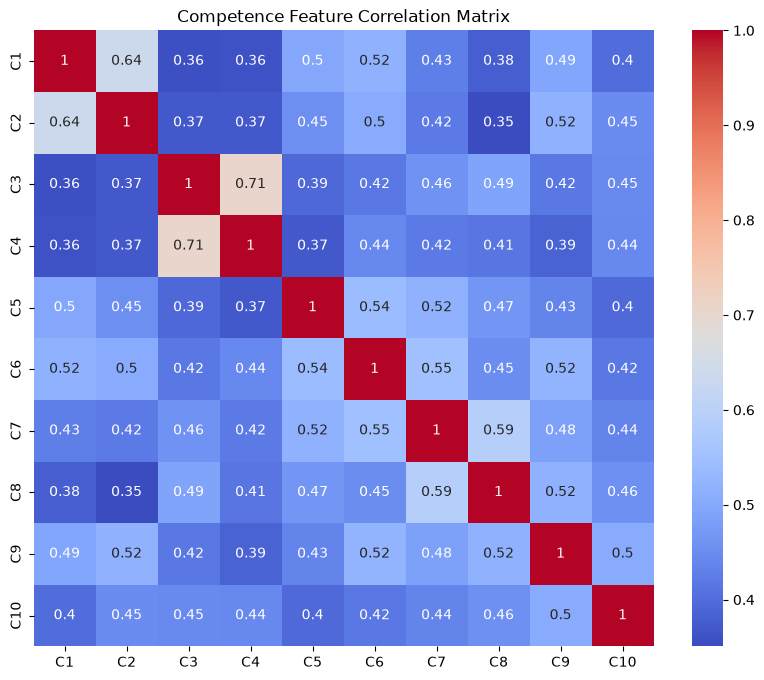

In [38]:
plt.figure(figsize=(10,8))


sns.heatmap(
    X_item.corr(),
    annot=True,
    cmap="coolwarm"
)


plt.title(
    "Competence Feature Correlation Matrix"
)


plt.show()

## Feature Distribution Analysis

Descriptive statistics were generated for all Competence features to understand their distribution before machine learning modelling.

The analysis includes:

- Mean
- Standard deviation
- Minimum value
- Maximum value

In [39]:
feature_distribution = df[
    competence_items
].describe().T


feature_distribution

,count,mean,std,min,25%,50%,75%,max
C1,1000.0,3.985,0.436997,1.0,4.0,4.0,4.0,5.0
C2,1000.0,3.985,0.457148,1.0,4.0,4.0,4.0,5.0
C3,1000.0,3.709,0.576760,1.0,3.0,4.0,4.0,5.0
C4,1000.0,3.680,0.598296,1.0,3.0,4.0,4.0,5.0
C5,1000.0,3.947,0.392868,1.0,4.0,4.0,4.0,5.0
C6,1000.0,4.003,0.434948,1.0,4.0,4.0,4.0,5.0
C7,1000.0,3.965,0.440419,1.0,4.0,4.0,4.0,5.0
C8,1000.0,3.877,0.487964,1.0,4.0,4.0,4.0,5.0
C9,1000.0,3.992,0.431419,1.0,4.0,4.0,4.0,5.0
C10,1000.0,3.875,0.497617,1.0,4.0,4.0,4.0,5.0


In [40]:
FEATURE_REPORT_DIR = (
    PROJECT_DIR
    /
    "reports"
    /
    "phase2"
    /
    "feature_engineering"
)


FEATURE_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


feature_distribution.to_csv(
    FEATURE_REPORT_DIR /
    "Feature_Distribution_Summary.csv"
)

## Outlier Analysis

Boxplot visualization was used to identify unusual response patterns among Competence variables.

Since questionnaire responses were measured using a 5-point Likert scale, extreme values within this range were considered valid responses.

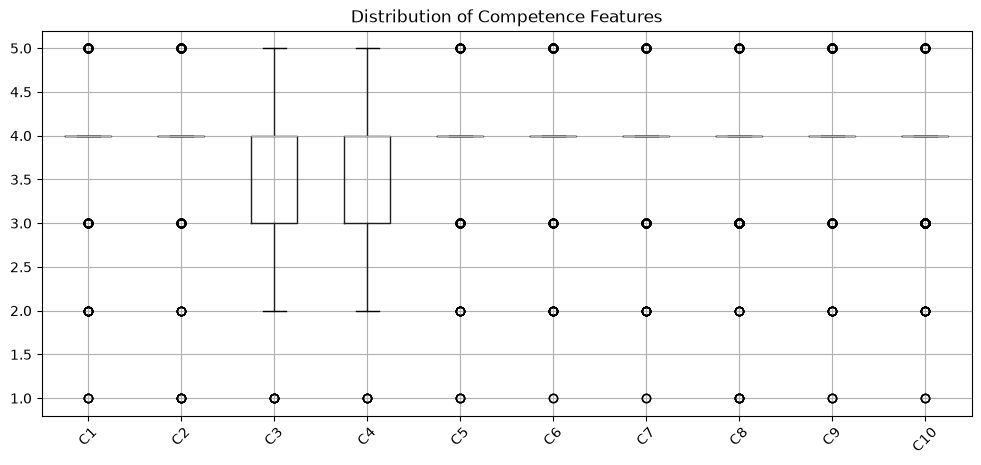

In [41]:
plt.figure(figsize=(12,5))


df[
    competence_items
].boxplot()


plt.title(
    "Distribution of Competence Features"
)


plt.xticks(
    rotation=45
)


plt.show()

## Feature Scaling Consideration

All Competence variables are measured using the same 5-point Likert scale.

Therefore:

- Tree-based models such as Random Forest and XGBoost do not require feature scaling.
- Scaling will be applied during model-specific preprocessing for algorithms such as Support Vector Regression and Linear Regression.

This approach maintains appropriate preprocessing for each machine learning algorithm.

Prepare Final ML Dataset

In [42]:
final_features = competence_items


ml_dataset = df[
    final_features + [TARGET]
]


ml_dataset.head()

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,EVS_avg
0,3,3,4,4,3,3,3,3,4,3,4.750000
1,3,4,4,3,4,4,4,4,4,3,3.500000
2,3,4,3,3,3,4,3,4,4,3,3.750000
3,4,4,4,4,4,4,4,4,4,3,4.000000
4,4,4,4,4,4,5,5,4,4,5,4.333333


"Outlier analysis was performed to identify unusual response patterns. Since all values were within the valid Likert scale range, no data correction was required."

## Feature Metadata Creation

Feature metadata was created to maintain interpretability of machine learning outputs.

The metadata maps questionnaire codes with their competency descriptions.

Dataset Validation

In [43]:
feature_metadata = pd.DataFrame({

"Feature":[
"C1",
"C2",
"C3",
"C4",
"C5",
"C6",
"C7",
"C8",
"C9",
"C10"
],


"Description":[

"Adaptability to changing situations",

"Communication with diverse team members",

"Project planning and execution",

"Leadership ability",

"Reasoning and decision making",

"Communication and collaboration",

"Creativity and innovation",

"Information access and evaluation",

"Media communication skills",

"Media analysis and creation"

]

})


feature_metadata

,Feature,Description
0,C1,Adaptability to changing situations
1,C2,Communication with diverse team members
2,C3,Project planning and execution
3,C4,Leadership ability
4,C5,Reasoning and decision making
5,C6,Communication and collaboration
6,C7,Creativity and innovation
7,C8,Information access and evaluation
8,C9,Media communication skills
9,C10,Media analysis and creation


In [44]:
feature_metadata.to_csv(
    FEATURE_REPORT_DIR /
    "Feature_Metadata.csv",
    index=False
)

In [45]:
print(
    "Final ML Dataset Shape:",
    ml_dataset.shape
)


print(
    "Missing Values:"
)


print(
    ml_dataset.isnull().sum()
)

Final ML Dataset Shape: (1000, 11)
Missing Values:
C1         0
C2         0
C3         0
C4         0
C5         0
C6         0
C7         0
C8         0
C9         0
C10        0
EVS_avg    0
dtype: int64


Save Feature Engineered Dataset

In [46]:
FEATURE_DIR = (
    PROJECT_DIR
    /
    "data"
    /
    "processed"
)


FEATURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [47]:
ml_dataset.to_csv(
    FEATURE_DIR /
    "phase2_competence_ml_features.csv",
    index=False
)

## Feature Selection Justification

The Competence questionnaire items (C1-C10) were retained as predictive features because each item demonstrated a positive relationship with Employability (EVS_avg).

Correlation analysis showed moderate positive associations between all competence items and employability, indicating that each competency dimension provides meaningful information for prediction.

Therefore, all validated competence items were included in the machine learning dataset to allow models to identify complex relationships among individual competence indicators.

## Feature Engineering Conclusion

Feature engineering was performed to prepare Competence variables for machine learning modelling.

The final feature set consisted of C1-C10 as independent variables and EVS_avg as the prediction target.

Correlation analysis confirmed that all competence items had positive associations with employability. The prepared dataset was validated with no missing values and is suitable for machine learning experiments.

Feature Set Comparison

"Why did you select C1-C10 instead of construct averages?"

## Final Feature Dataset Validation

The final machine learning dataset was validated before model development.

The validation checks include:
- Dataset dimensions
- Missing values
- Feature columns
- Target variable availability

In [ ]:
print("Dataset Shape:")
print(ml_dataset.shape)


print("\nFeature Columns:")
print(final_features)


print("\nTarget Variable:")
print(TARGET)


print("\nMissing Values:")
print(ml_dataset.isnull().sum())

Dataset Shape:
(1000, 11)

Feature Columns:
['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10']

Target Variable:
EVS_avg

Missing Values:
C1         0
C2         0
C3         0
C4         0
C5         0
C6         0
C7         0
C8         0
C9         0
C10        0
EVS_avg    0
dtype: int64
